# 06 — Rastgele Orman ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Rastgele orman, çok sayıda karar ağacını farklı bootstrap örneklemleri ve her
bölünmede farklı özellik alt kümeleri üzerinde eğitip sonuçlarını birleştirir
(bagging). Tek ağacın aşırı öğrenme zaafını topluluk gücüyle telafi eder; genellikle
ayar yapılmadan dahi iyi sonuç verir. Ölçekleme gerektirmez ve özellik önemlerini
doğrudan raporlar. Model 200 ağaçla ve yaprak başına en az **1** örnek koşuluyla
(doğrulama kümesiyle seçildi) kurulmuştur.

**Tekrar üretilebilirlik notu.** Orman tek iş parçacığıyla (`n_jobs=1`) çalıştırılır. Paralel
çalıştırmada ağaçların tahminleri iş parçacıklarının bitiş sırasına göre toplanır; toplama sırası
her çalıştırmada değiştiği için son ondalık basamaklarda yuvarlama farkları ve az ağaçlı ormanlarda
eşit oylu sınıfların farklı çözülmesi görülebilir. Tek iş parçacığı her çalıştırmada aynı sonucu verir.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
reg_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                  random_state=42, n_jobs=1)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1528
   MSE: 0.0621
  RMSE: 0.2493
    R2: 0.7514
   AUC: 0.9734


In [3]:
o.reg_grafikleri(yr_te, y_pred, "Rastgele Orman", "rastgele_orman")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\rastgele_orman_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, class_weight='balanced',
                             random_state=42, n_jobs=1)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9243
   BalancedAcc: 0.9245
      F1_macro: 0.9243
   F1_weighted: 0.9243

              precision    recall  f1-score   support

  Yangın Yok      0.934     0.916     0.925       653
      Yangın      0.914     0.933     0.924       629

    accuracy                          0.924      1282
   macro avg      0.924     0.925     0.924      1282
weighted avg      0.925     0.924     0.924      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1528 |   0.4998 |    0.3931 | -0.2402 (iyi)
     MSE |   0.0621 |   0.2499 |    0.1978 | -0.1357 (iyi)
    RMSE |   0.2493 |   0.4999 |    0.4447 | -0.1955 (iyi)
      R2 |   0.7514 |  -0.0000 |    0.2086 | +0.5428 (iyi)
     AUC |   0.9734 |   0.5000 |    0.6982 | +0.2752 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9243 |   0.5094 |    0.6934 | +0.2309
     BalancedAcc |  0.9245 |   0.5000 |    0.6982 | +0.2263
        F1_macro |  0.9243 |   0.3375 |    0.6748 | +0.2495
     F1_weighted |  0.9243 |   0.3438 |    0.6733 | +0.2510
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "Rastgele Orman", "rastgele_orman")

Rastgele Orman — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   598     55
      Yangın |    42    587


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\rastgele_orman_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### Özellik Önemleri ve Ağaç Sayısının Etkisi

Özellik önemi, bir değişkenin bölünmelerde sağladığı ortalama saflık (safsızlık
azalması) kazancıdır. Aşağıda önce hangi özelliğin modele ne kadar katkı verdiği
görülür, ardından orman büyüklüğünün (ağaç sayısı) performansı nerede doyurduğu ölçülür.

In [7]:
o.ozellik_onem_grafigi(clf.feature_importances_, "Rastgele Orman", "rastgele_orman")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\rastgele_orman_onem.png'

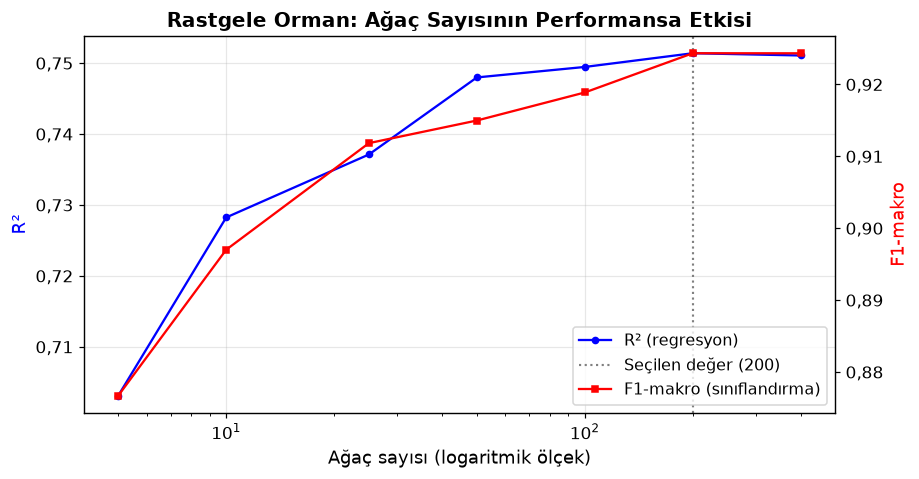

Tarama: [(5, 0.7031, 0.8767), (10, 0.7282, 0.897), (25, 0.7371, 0.9118), (50, 0.748, 0.915), (100, 0.7495, 0.9189), (200, 0.7514, 0.9243), (400, 0.7511, 0.9243)]
En yüksek R²: 0.7514 (200) · en yüksek F1-makro: 0.9243 (200)


In [8]:
degerler = [5, 10, 25, 50, 100, 200, 400]
r2_list, f1_list = [], []
for n in degerler:
    r = RandomForestRegressor(n_estimators=n, min_samples_leaf=1, random_state=42, n_jobs=1).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = RandomForestClassifier(n_estimators=n, min_samples_leaf=1, class_weight='balanced',
                               random_state=42, n_jobs=1).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(200, color="gray", ls=":", lw=1.4, label="Seçilen değer (200)")
ax1.set_xlabel("Ağaç sayısı (logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("Rastgele Orman: Ağaç Sayısının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "rf_nest_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [9]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = RandomForestRegressor(n_estimators=200, min_samples_leaf=1, random_state=42, n_jobs=1).fit(Xa, yra).predict(Xb)
    c_tahmin = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, class_weight='balanced', random_state=42, n_jobs=1).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2068 · F1-makro 0.7744


  kat 2: eğitim  4170 · sınama   958 · R² +0.2194 · F1-makro 0.6322


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5672 · F1-makro 0.8412


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4434 · F1-makro 0.8368


  kat 5: eğitim  4150 · sınama   978 · R² +0.5138 · F1-makro 0.8752
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3901 ± 0.1499
  F1-makro: 0.7920 ± 0.0862


In [10]:
o.sonuc_kaydet("rastgele_orman", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\rastgele_orman.json


{'algoritma': 'rastgele_orman',
 'regresyon': {'MAE': 0.15281201248049922,
  'MSE': 0.06213102574102965,
  'RMSE': 0.24926095911921234,
  'R2': 0.7513887671429649,
  'AUC': 0.9733710379147728},
 'siniflandirma': {'Accuracy': 0.9243369734789392,
  'BalancedAcc': 0.9245003493719826,
  'F1_macro': 0.9243314025835416,
  'F1_weighted': 0.9243435572644091},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.20675680150012066,
    0.2193687495629676,
    0.5671989518039944,
    0.4433956991068947,
    0.513823860441767],
   'F1_macro': [0.7743649670951473,
    0.6322411273744954,
    0.8412234459000991,
    0.8368137861593001,
    0.8752368404542317],
   'R2_ort': 0.3901088124831489,
   'R2_std': 0.14985056011883277,
   'F1_ort': 0.7919760333966548,
   'F1_std': 0.08624787946512277},
  'duyarlilik': {'degerler': [5.0, 10.0, 25.0, 50.0, 100.0, 200.0, 400.0],
   'R2': [0.7031096784560436,
    0.728235488889484,
    0.7371134833238788,
    0.7479778213309247,
    0.749455718379401,
    0.7513